In [13]:
import numpy as np
import pyvisa
import matplotlib.pyplot as plt
import time
import random 
from IPython.display import display, clear_output
import scipy.interpolate as interp

def plotStandards():
    plt.tick_params( axis='both', which='both',direction='in', right=True,labelright=True)
    plt.minorticks_on()
    plt.grid(True)
    
def axStandards(ax, xlabel , ylabel):
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='both', which='both', direction='in', right=True, labelright=True)
    ax.minorticks_on()
    ax.grid(True)

In [14]:
rm = pyvisa.ResourceManager()
resources = rm.list_resources()
print("Available Resources", resources)

powerSupply = rm.open_resource('GPIB::5::INSTR')
bottomKDMM = rm.open_resource('GPIB::2::INSTR')
middleKDMM = rm.open_resource('GPIB::1::INSTR')
#print(middleKDMM.query('*IDN?'))

#print(powerSupply.query('*IDN?'))
#print( powerSupply.query("MEAS:VOLT?") )
#powerSupply.write('INST:NSEL 3')
#powerSupply.write('SOUR:VOLT 5')
#powerSupply.write('SOUR:CURR 5')
#powerSupply.write('OUTP ON')

def setPower(psObject , outpNumber , volts , current):
    psObject.write(f'INST:NSEL {outpNumber}')
    psObject.write(f'SOUR:VOLT {volts}')
    psObject.write(f'SOUR:CURR {current}')
    psObject.write('OUTP ON')
    
    
setPower(powerSupply , 3 , 5 , 5 )
print( powerSupply.query("MEAS:VOLT?") )
print( powerSupply.query("MEAS:VOLT?") )

#PS.write('OUTP OFF')


#PS.write('INST:NSEL 3')
#PS.write('SOUR:VOLT 6')
#PS.write('SOUR:CURR .4')

#PS.write('OUTP ON')

#print('\n')
#print(middleKDMM.query("MEAS:RES?"))
#print(bottomKDMM.query("MEAS:RES?"))

Available Resources ('GPIB0::1::INSTR', 'GPIB0::2::INSTR', 'GPIB0::5::INSTR', 'GPIB0::16::INSTR', 'GPIB0::18::INSTR', 'GPIB0::19::INSTR', 'USB0::0x2A8D::0x1102::MY61001264::0::INSTR')
0.500E+1

0.500E+1



In [3]:
# defining manual based values
temps = [60,55,50,45,40,35,30,25,20,15,10,5,0,-5,-10,-15,-20,-25,-30,-35,-40]
tempsK = 273.15*np.ones(np.size(temps))
tempsK[:] = tempsK[:] + temps[:] # converts to Kelvin
# from data sheet from Vishney or whatever teh company is called
Rs = [587.4, 690.5, 814.7, 965.4, 1149, 1375, 1653, 2000, 2434, 2981, 3675, 4563, 5707, 7193, 9138, 11709, 15138, 19754, 26035, 34672, 46684]


# make the spline
# resistance goes in amd temperature in kelvin comes out
# Temperature = Res2TempsK(Resistance)
Res2TempsK = interp.make_interp_spline(Rs, tempsK, k=3)

# and for celsius
Res2TempsC = interp.make_interp_spline(Rs, temps, k=3)

        
        

In [22]:
setPower(powerSupply , 2  , 6 ,1 )

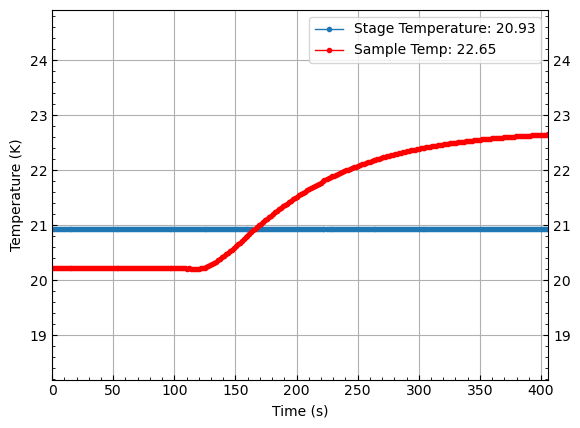

In [ ]:

#Room temp ~20.9
targetTemp = 21
sampleTarget = targetTemp + 2

stageTemp = [Res2TempsC(float(bottomKDMM.query("MEAS:RES?")))]
sampleTemp=  [Res2TempsC(float(middleKDMM.query("MEAS:RES?")))]
timeVals = [0]
yScale = 0.1 # +/- yVal * 0.1
setVolts = 0
    

fig = plt.figure()
ax = fig.add_subplot(111)
disp = display(fig, display_id=True)
plt.close(fig)


lastTagged =  time.time()*1.0


#Set the power for the sample heater coil
setPower(powerSupply , 1, volts=5,current =0.1 )


#voltArr = np.array([])


count = 0


eqTime = 0 

#reachedTarget = False

while eqTime < 60:
    
    
    if sampleTemp[-1] > sampleTarget:
       
        eqTime = eqTime + 1
    
    
    #Get the temperature
    stageT =   Res2TempsC( float(bottomKDMM.query("MEAS:RES?")) )  #Res2TempsK if we want kelvin
    sampleT = Res2TempsC( float(middleKDMM.query("MEAS:RES?"))  )
    #add to array
    stageTemp.append(stageT)
    sampleTemp.append(sampleT)
    
    
    
    #get system time and measure from last tagged time to get the x axis time
    currentTime = time.time()*1.0
    timeVals.append( timeVals[-1] + currentTime - lastTagged)
    lastTagged =  time.time()*1.0
    
    
    #clear the previous--> set axis standards
    ax.clear()
    axStandards(ax,"Time (s)" , "Temperature (K)")
    

    
    bottomLimit = min(np.array([min(stageTemp),min(sampleTemp)]) )
    topLimit = max(np.array([max(stageTemp),max(sampleTemp)]) )
    bottomLimit = bottomLimit -  bottomLimit*yScale
    topLimit = topLimit + topLimit*yScale
        
    ax.set_ylim(bottomLimit , topLimit)
    ax.set_xlim(timeVals[0],timeVals[-1])
    
    
    ###########
    #End of loop temperature control for targets above room temperature
    error =  np.abs(stageT - targetTemp)
    
    #print( stageT - targetTemp )
    
    
    
    
    if stageT > targetTemp:
        setVolts=0
        setPower( powerSupply , 2 , volts=setVolts , current=5)
    else:
        #count = count + 1
        setVolts = 1.5*error**0.25
       
        #if count > 1 :
            #setVolts = 1.00*np.average( voltArr > 0 ) 
        
        if setVolts > 10:
            setPower(powerSupply , 2 , volts=10,current =5 )
        else:
            setPower(powerSupply , 2, volts=setVolts,current =5 )

    
    #voltArr = np.append(voltArr, setVolts)
    
   

    #do the final plotting
    ax.plot(timeVals , stageTemp   , "-o",linewidth=1, markersize=3,label=f'Stage Temperature: {stageT:.2f}')
    ax.plot(timeVals ,  sampleTemp ,  "r-o",linewidth=1, markersize=3,label=f'Sample Temp: {sampleT:.2f}')
    ax.legend() 
    #update the plot 
    disp.update(fig) 
    
   
    
    
        

        

In [31]:
import pandas as pd
import numpy as np

# create a dummy array
arr = np.vstack( ( np.array(timeVals).T ,np.array(stageTemp).T ,np.array(sampleTemp).T  )).T
print(arr.shape)
print(arr)
# convert array into dataframe
DF = pd.DataFrame(arr)

# save the dataframe as a csv file
DF.to_csv("4-21_20C.csv")

(261, 3)
[[  0.          19.99348739  19.4739006 ]
 [  1.38736773  19.99102962  19.4739346 ]
 [  3.01296329  19.98749917  19.47372431]
 [  4.67529964  19.98386705  19.47374754]
 [  6.33129287  19.98056709  19.47355888]
 [  7.99121594  19.97795443  19.47355676]
 [  9.65214515  19.97624658  19.47350256]
 [ 11.26955581  19.97551775  19.47327518]
 [ 12.91527534  19.97544509  19.47303342]
 [ 14.55477118  19.97637935  19.47291516]
 [ 16.20264626  19.97765791  19.47256178]
 [ 17.84871268  19.97972026  19.47256158]
 [ 19.52085543  19.9821676   19.47228765]
 [ 21.17902327  19.9849734   19.47209769]
 [ 22.87276101  19.98759874  19.47171185]
 [ 24.55739522  19.98965821  19.47143481]
 [ 26.24798918  19.99134867  19.47147634]
 [ 27.91131639  19.99188956  19.47113566]
 [ 29.57202983  19.99176989  19.47111424]
 [ 31.22612691  19.99072128  19.47086758]
 [ 32.88902164  19.98899236  19.4705997 ]
 [ 34.54766917  19.98666957  19.4705437 ]
 [ 36.22999477  19.98443257  19.47033958]
 [ 37.91179252  19.982490